# Entrega final: Tiamat

Esta é a entrega final da disciplina de aprendizado de máquina, ministrada pelo prof. Dr. Daniel Roberto Cassar, para a turma de 2026 da Ilum escola de ciência. Feito pelo discente Álex V. R. Araujo, este caderno serve como complemento ao ``README.md`` deste repositório, concentrando debates mais específicos acerca das escolhas feitas, o tratamento dos dados e resultados. 

## Importações dos módulos

In [1]:
import sys, platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import sklearn
from sklearn.model_selection import train_test_split, KFold, GroupKFold, cross_val_score
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline

optuna.logging.set_verbosity(optuna.logging.WARNING)

SEMENTE = 12151822

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

### Localização do repositório

Por ter tido problemas com caminhos, pedi ao Claude para ajustar esta parte.

In [2]:
import os
from pathlib import Path

def achar_raiz(profundidade=3) -> Path:
    """Raiz = pasta que contém 'data/' e 'otimizacao/'. Sobe a partir da pasta atual e, se preciso, desce até 3 níveis."""
    inicio = Path.cwd().resolve()
    eh_raiz = lambda p: (p / "data").is_dir() and (p / "otimizacao").is_dir()
    for pasta in [inicio, *inicio.parents]:
        if eh_raiz(pasta):
            return pasta
    for atual, subs, _ in os.walk(inicio):
        nivel = len(Path(atual).relative_to(inicio).parts)
        if nivel >= profundidade:
            subs[:] = []
        elif eh_raiz(Path(atual)):
            return Path(atual)
    raise FileNotFoundError("Não achei a raiz do repositório (pasta com 'data/' e 'otimizacao/'). "
                            "Defina manualmente: RAIZ = Path('/caminho/do/repositorio')")

RAIZ = achar_raiz()

DADOS = RAIZ / "data" / "train.csv"
FIG = RAIZ / "figuras"; FIG.mkdir(exist_ok=True)

ARQ_OTM = RAIZ / "otimizacao" / "otimizacao.py"
if not ARQ_OTM.exists():                                   # se o arquivo estiver em outra subpasta
    ARQ_OTM = next(RAIZ.rglob("otimizacao.py"), None)
    if ARQ_OTM is None:
        raise FileNotFoundError("otimizacao.py não encontrado sob " + str(RAIZ))
PASTA_OTM = ARQ_OTM.parent
TTV = PASTA_OTM / "data_TTV"; TTV.mkdir(exist_ok=True)    # df_treino.csv, df_val.csv, df_teste.csv
RES = PASTA_OTM                                            # candidatos.csv, resultados.csv, preds_teste.npz

sys.path.insert(0, str(PASTA_OTM))                         # permite `from otimizacao import ...`
print("Raiz do repositório:", RAIZ)
print("otimizacao.py em   :", ARQ_OTM.relative_to(RAIZ))

Raiz do repositório: C:\Users\alex2610082\OneDrive - ILUM ESCOLA DE CIÊNCIA\Documentos\Alex-Ilum-T26
otimizacao.py em   : otimizacao\otimizacao.py


## Divisão de treino, teste e validação e exportação dos DataFrames

Aqui é realizada a divisão de treino, teste e validação nas proporções 60/20/20, respectivamente. Depois, são formados DataFrames com cada repartição e exportados para serem usados nas demais etapas do código.

In [3]:
df = pd.read_csv(DADOS)
X = df.drop("critical_temp", axis=1)
y = df[["critical_temp"]]

X_treino, X_tv, y_treino, y_tv = train_test_split(X, y, test_size=0.4, random_state=SEMENTE)
X_val, X_teste, y_val, y_teste = train_test_split(X_tv, y_tv, test_size=0.5, random_state=SEMENTE)

Criando e salvando os DataFrames:

In [5]:
# caminhos ajustados (TTV é definido em 'Localização do repositório')
df_treino = pd.concat([X_treino, y_treino], axis=1)
df_treino.to_csv(TTV / 'df_treino.csv', index=False)

df_teste = pd.concat([X_teste, y_teste], axis=1)
df_teste.to_csv(TTV / 'df_teste.csv', index=False)

df_val = pd.concat([X_val, y_val], axis=1)
df_val.to_csv(TTV / 'df_val.csv', index=False)

Agora eles estão prontos para serem usados a qualquer momento. Isto também serve para garantir que não haverá mudanças nas repartições básicas entre um script e outro.

## Análise exploratória no DataSet de treino

Aqui, vamos observar como nosso alvo está distribuído e quantos materiais temos por número de elementos. Como as propriedades dos materiais dependem intrinsecamente de seus elementos, vale dar uma conferida.

### Distribuição do alvo

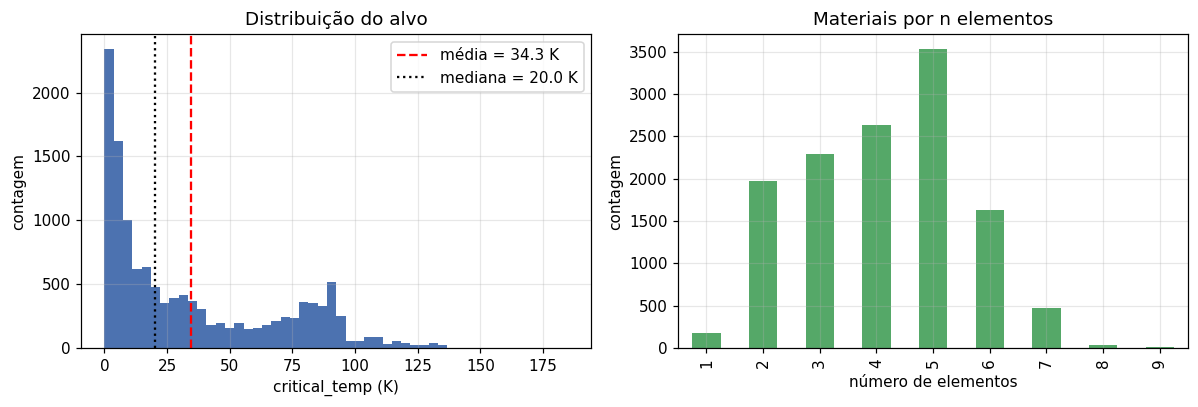

assimetria: 0.86


In [ ]:
alvo = y_treino["critical_temp"]

figura, eixo = plt.subplots(1, 2, figsize=(11, 3.8))
eixo[0].hist(alvo, bins=50, color="#4c72b0")

eixo[0].axvline(alvo.mean(), c="r", ls="--", label=f"média = {alvo.mean():.1f} K")

eixo[0].axvline(alvo.median(), c="k", ls=":", label=f"mediana = {alvo.median():.1f} K")

eixo[0].set(xlabel="critical_temp (K)", ylabel="contagem", title="Distribuição do alvo"); eixo[0].legend()

n_elementos = X_treino["number_of_elements"].value_counts().sort_index()
n_elementos.plot.bar(ax=eixo[1], color="#55a868")

eixo[1].set(xlabel="número de elementos", ylabel="contagem", title="Materiais por n elementos")

plt.tight_layout() 
#plt.savefig(FIG / "distribuicao_alvo.png", dpi=200)
plt.show()

print("assimetria:", round(alvo.skew(), 2))

Aqui fica evidente que os dados são muito assimétricos para a direita, tendo menos observações de materiais de temperatura crítica alta, isto pode se traduzir em erros maiores quando os algoritmos forem prever supercondutores com temperaturas mais altas, salvo aqueles entre 75 e 100K°, por terem uma quantidade um pouco maior de exemplos.

Além disso, há muito mais materiais com número de elementos entre 2 e 5, enquanto aqueles com 1 elemento e de 6 a 9 elementos também tem pouca representatividade nos dados.

### E quanto às distribuições de alvo das partições?

Vamos verificar se as partições têm, pelo menos, distribuições comparáveis:

In [8]:
pd.DataFrame({"treino": y_treino["critical_temp"].describe(),
              "validação": y_val["critical_temp"].describe(),
              "teste": y_teste["critical_temp"].describe()}).round(2)

,treino,validação,teste
count,12757.00,4253.00,4253.00
mean,34.33,34.43,34.67
std,34.18,34.22,34.53
min,0.00,0.00,0.00
25%,5.40,5.50,5.13
50%,20.00,20.00,20.00
75%,63.00,62.00,63.80
max,185.00,135.70,143.00


Elas possuem pequenas ínfimas entre si, com a única diferença significativa sendo o máximo que só aparece na partição de treino.

                             pearson  spearman
wtd_std_ThermalConductivity    0.717     0.709
range_ThermalConductivity      0.684     0.720
std_ThermalConductivity        0.651     0.621
range_atomic_radius            0.649     0.752
wtd_mean_Valence              -0.631    -0.734
wtd_entropy_atomic_mass        0.619     0.701
wtd_gmean_Valence             -0.614    -0.734
mean_Valence                  -0.598    -0.684
range_fie                      0.597     0.660
wtd_std_atomic_radius          0.596     0.677
wtd_entropy_atomic_radius      0.596     0.680
number_of_elements             0.593     0.663
entropy_Valence                0.591     0.686
wtd_entropy_Valence            0.581     0.658
wtd_std_fie                    0.579     0.587


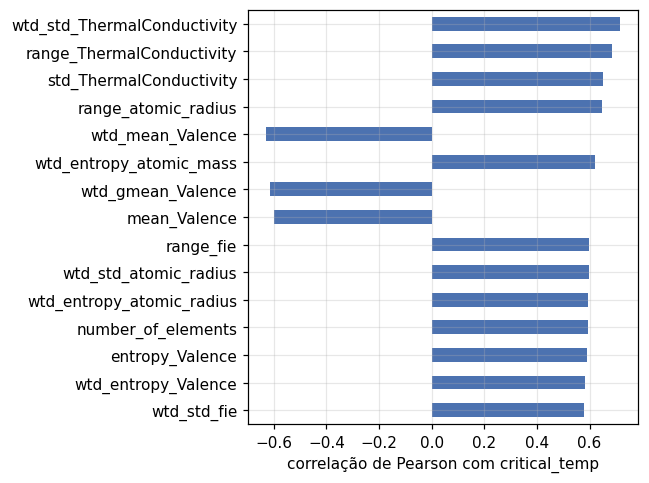

In [ ]:
dados = X_treino.assign(critical_temp=alvo)

vals_pearson = dados.corr()["critical_temp"]
vals_spearman = dados.corr(method="spearman")["critical_temp"]

df_corr = pd.DataFrame({"pearson": vals_pearson,
                     "spearman": vals_spearman}).drop("critical_temp")

melhores_pearson = df_corr.reindex(df_corr["pearson"].abs().sort_values(ascending=False).index).head(15)

print(melhores_pearson.round(3))
melhores_pearson["pearson"][::-1].plot.barh(figsize=(6, 4.5), color="#4c72b0")
plt.xlabel("correlação de Pearson com critical_temp")
plt.tight_layout()
#plt.savefig("./figuras/pearson_alvo.png", dpi=200)
plt.show()

                             pearson  spearman
range_atomic_radius            0.649     0.752
wtd_mean_Valence              -0.631    -0.734
wtd_gmean_Valence             -0.614    -0.734
range_ThermalConductivity      0.684     0.720
wtd_std_ThermalConductivity    0.717     0.709
wtd_entropy_atomic_mass        0.619     0.701
entropy_Valence                0.591     0.686
mean_Valence                  -0.598    -0.684
wtd_entropy_atomic_radius      0.596     0.680
wtd_std_atomic_radius          0.596     0.677
number_of_elements             0.593     0.663
gmean_Valence                 -0.572    -0.661
range_fie                      0.597     0.660
wtd_entropy_Valence            0.581     0.658
entropy_FusionHeat             0.547     0.637


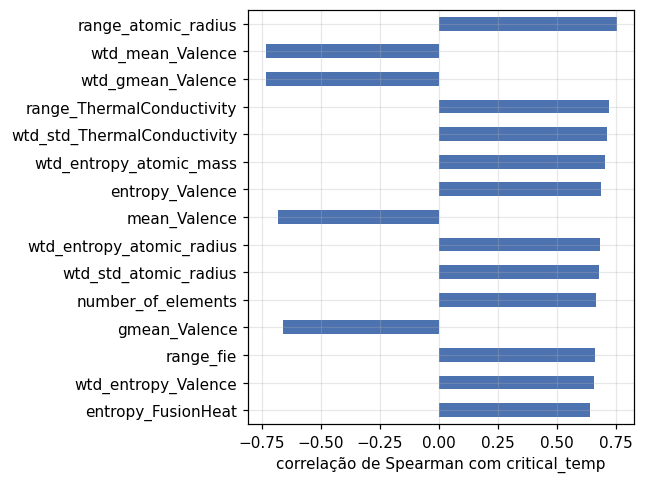

In [ ]:
melhores_spearman = df_corr.reindex(df_corr["spearman"].abs().sort_values(ascending=False).index).head(15)

print(melhores_spearman.round(3))
melhores_spearman["spearman"][::-1].plot.barh(figsize=(6, 4.5), color="#4c72b0")
plt.xlabel("correlação de Spearman com critical_temp")
plt.tight_layout()
#plt.savefig("./figuras/spearman_alvo.png", dpi=200)
plt.show()

Estes plots revelam os atributos mais correlatos com o alvo, como muitos deles são estatísticas derivadas de uma propriedade (como os top 3 sendo referentes à condutividade térmica para Pearson), é esperado que apareçam repetições. Além disso, eles tem valores muito próximos, modelos lineares podem ter desempenho menor.

Uma curiosidade: a valência possui correlação negativa com a temperatura crítica, isto indica que materiais com valência menor estão correlacionados a temperaturas críticas mais alta. Apesar não necessariamente implicar em causalidade, pode ser interessante investigar futuramente.

Nota: Pearson mede a correlação linear entre o atributo e o alvo, enquanto Spearman pode medir relações monotônicas, reforçando a importância de olhar com maior atenção para algoritmos não lineares.

### Redundância entre atributos

Como visto qualitativamente no plot anterior, diversos atributos são estatísticas derivadas das propriedades dos materiais. Uma boa estratégia é usar seleção de features, bem como normalização de dados para garantir que algoritmos sensíveis à escala e redundância não sejam tão afetados.

## Metodologia

**Partições**: Os dados foram particionados em treino, teste e validação com 60%, 20% e 20% cada, respectivamente, com a semente. O treino serve para a otimização de hiperparâmetros dos algoritmos; a validação será usada para escolher o melhor dentre os 15 melhores estimadores treinados e otimizados com a partição anterior para cada algoritmo; teste, enfim, será usado como uma medida final, sendo rodado apenas uma vez e computando os resultados finais.

**Pipeline**: É usado o ``SelectPercentile(f_regression)`` para selecionar os X% atributos mais relevantes e diminuir a quantidade de dados redundantes -> para o KNN e o Ridge, o ``RobustScaler`` é empregado para evitar que dados anômalos ou de escalas muito diferentes atrapalhem o desempenho dos modelos -> enfim, o modelo é induzido. Todas estas etapas são otimizadas usando optuna.

**Métricas**: RMSE é usado como métrica principal para estimar os desempenhos dos modelos durante a otimização. Em seguida, r² e MAE (recomendação do claude) são usados para complementar as estimativas de desempenho.

**Validação cruzada**: 5 folds embaralhados com pontuação dada pelo pior valor dentre a média e a mediana dos folds de um trial. É uma maneira de impedir que as estimativas sejam superestimadas por conta de folds favoráveis.

**Busca de hiperparâmetros**: Realizada em 3 ciclos de refinamento do espaço de busca. O primeiro ciclo usou um espaço de busca abrangente com hiperparâmetros recomendados pelo Claude, foram plotados gráficos com os hiperparâmetros mais frequentes dos 25% melhores estimadores de cada algoritmo dos ensaios (ou studies) e os intervalos foram ajustados com base nas faixas observadas. Passados os 3 ciclos, foi realizada uma última otimização de hiperparâmetros com o espaço de busca ajustado. A busca de hiperparâmetros foi feita usando o HPC.

**Stacking**: Apelidado carinhosamente de Exodia, este meta-modelo combina modelos de diferentes naturezas onde é esperado que errem de formas diferentes e por motivos diferentes durante o treinamento, é estimado que ele generalize melhor para dados novos. Ele passa por validação cruzada aninhada com 3 folds internos e 5 folds externos e otimiza a escolha do ``passthrough`` para treinar apenas com as previsões dos estimadores iniciais (False), ou também com o conjunto de dados (True).

**Baseline**: A fim de ter uma medida de base para estimar o desempenho dos modelos, eles são comparados com um ``DummyRegressor`` que sempre prevê a média dos dados, tendo RMSE em torno de 34K°, sendo aproximadamente o desvio padrão dos dados (vide seção de distribuição de alvos por partições).

**Seleção de algoritmos**: Os 5 melhores estimadores de cada algoritmo são testados no DataSet de validação, são calculadas as métricas de RMSE, r² e MAE para os estimadores, o melhor de cada algoritmo é escolhido e usado no DataSet de Teste uma única vez.

## Ciclos de refinamento da otimização

Aqui, serão comparados os espaços de busca dos algoritmos em seus ciclos iniciais, com todos os trials plotados, e finais, com apenas os 25% melhores:

### KNN

#### Inicial
![KNN_c1](./figuras/KNN_i.png)

#### Terceiro ciclo
![KNN_c3](./figuras/KNN_f.png)

### HGB

#### Inicial
![HGB_c1](./figuras/HGB_i.png)

#### Terceiro ciclo
![HGB_c3](./figuras/HGB_f.png)

### Ridge

#### Inicial
![RIDGE_c1](./figuras/RIDGE_i.png)

#### Terceiro ciclo
![RIDGE_c3](./figuras/RIDGE_f.png)

### ETR

Por ser custoso, a otimização deste algoritmo foi limitada a dois ciclos.

#### Inicial
![ETR_c1](./figuras/ETR_i.png)

#### Segundo ciclo
![ETR_c32](./figuras/ETR_f.png)

### Exodia

Como este já usa um espaço de busca mais específico desde o início, não foram realizados mais ciclos de refinamento.

#### Ciclo único
![Exodia](./figuras/EXODIA_otm.png)


### Análise qualitativa

Após analisar qualitativamente os gráficos dos 25% melhores estimadores, os espaços de busca de hiperparâmetros para cada algoritmo foram reajustados para aqueles que constam atualmente em ``otimizacao.py`` e faixas semelhantes foram usadas também no espaço de busca do Exodia.

## Seleção dos modelos

Para cada algoritmo, os 15 melhores trials do último ciclo, estimados pelo RMSE da validação cruzada, foram ajustados no DataSet de treino e avaliados na partição de validação. O melhor de cada algoritmo, de menor RMSE na validação, foi enfim avaliado uma única vez no conjunto de teste. A otimização rodou integralmente no HPC, enquanto as etapas de validação e testes foram executadas neste caderno, usando os estudos salvos. Usei o Claude para fazer esta sessão, tive muita dificuldade na hora de implementá-la.

### Preparação

In [ ]:
import json, time
os.environ["SLURM_CPUS_PER_TASK"] = str(os.cpu_count())

from optuna.trial import FixedTrial
from otimizacao import instanciar_modelo, exodia

from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

X_tr, y_tr = X_treino, y_treino["critical_temp"].values
X_va, y_va = X_val, y_val["critical_temp"].values
X_te, y_te = X_teste, y_teste["critical_temp"].values

ALGS = {"Ridge": Ridge, "KNN": KNeighborsRegressor,
        "HGB": HistGradientBoostingRegressor, "ETR": ExtraTreesRegressor}

def construir(nome, trial):
    if nome == "Exodia":
        return exodia(trial, cv=3)
    return instanciar_modelo(ALGS[nome], trial)

def metricas(y_real, y_prev):
    return {"rmse": root_mean_squared_error(y_real, y_prev),
            "mae": mean_absolute_error(y_real, y_prev),
            "r2": r2_score(y_real, y_prev)}

K = 5

ESTUDOS = {
    "Ridge" : ("otimizacao/E_RIDGE/studies/RIDGE_ciclo4.db", "RIDGE_ciclo3"),
    "KNN" : ("otimizacao/E_KNN/studies/KNN_ciclo3.db", "KNN_ciclo3"),
    "HGB" : ("otimizacao/E_HGB/HGB_ciclo3.db", "HGB_ciclo3"),
    "ETR" : ("otimizacao/E_ETR/studies/ETR_ciclo3_corr.db", "ETR_ciclo3_corr"),
    "Exodia" : ("otimizacao/E_EXODIA/studies/Exodia_otm.db", "Exodia_otm"),
}

### Candidatos na validação

Aqui validamos 5 melhores modelos e salvamos num .csv para não precisar rodar novamente.

In [34]:
candidatos = RES / "candidatos.csv"
if candidatos.exists():
    linhas = pd.read_csv(candidatos).to_dict("records") 
else: 
    linhas = []

feitos = {(l["modelo"], int(l["trial"])) for l in linhas}

for nome, (db, nome_estudo) in ESTUDOS.items():
    url = f"sqlite:///{(RAIZ / db).resolve().as_posix()}"
    estudo_ = optuna.load_study(study_name=nome_estudo, storage=url)

    concluidos = [t for t in estudo_.trials if t.state.name == "COMPLETE"]
    melhores = sorted(concluidos, key=lambda t: t.value, reverse=True)[:K]

    for t in melhores:
        if (nome, t.number) in feitos:
            continue
        inicio = time.perf_counter()
        modelo = construir(nome, FixedTrial(t.params)).fit(X_tr, y_tr)
        tempo = time.perf_counter() - inicio
        pontos = metricas(y_va, modelo.predict(X_va))

        linhas.append({"modelo": nome, "trial": t.number, "rmse_cv": -t.value,
                       "rmse_val": pontos["rmse"], "mae_val": pontos["mae"], "r2_val": pontos["r2"],
                       "tempo_fit": round(tempo, 1), "params": json.dumps(t.params)})
        pd.DataFrame(linhas).to_csv(candidatos, index=False)
        print(f"{nome:8s} trial {t.number:>4}  CV = {-t.value:7.3f}  validação = {m['rmse']:7.3f}  ({tempo:.0f} s)", flush=True)

Carregando o DataFrame:

In [35]:
df_candidatos = pd.read_csv(RES / "candidatos.csv")
df_candidatos[["modelo", "trial", "rmse_cv", "rmse_val"]].sort_values(["modelo", "rmse_val"]).round(3)

,modelo,trial,rmse_cv,rmse_val
9,ETR,61,9.996,9.203
10,ETR,97,9.997,9.224
22,ETR,90,10.002,9.224
21,ETR,71,10.002,9.230
11,ETR,80,10.001,9.242
23,Exodia,72,9.931,9.078
24,Exodia,19,9.932,9.099
14,Exodia,70,9.931,9.111
13,Exodia,82,9.930,9.117
12,Exodia,43,9.927,9.118


Vamos plotar os candidatos:

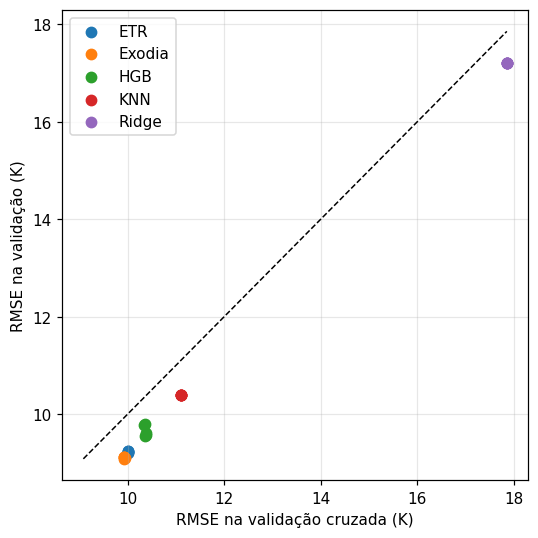

In [36]:
figura, eixo = plt.subplots(figsize=(5, 5))
for nome, g in df_candidatos.groupby("modelo"):
    eixo.scatter(g["rmse_cv"], g["rmse_val"], label=nome, s=45)

limite = [df_candidatos[["rmse_cv", "rmse_val"]].min().min(), df_candidatos[["rmse_cv", "rmse_val"]].max().max()]

eixo.plot(limite, limite, "k--", lw=1)
eixo.set(xlabel="RMSE na validação cruzada (K)", ylabel="RMSE na validação (K)")
eixo.legend()
plt.tight_layout()
plt.show()

A diagonal é descrita pelo valor mínimo entre o RMSE na validação cruzada e o RMSE na partição de validação para o eixo X. No eixo y, ela é descrita pelo valor máximo entre estas duas grandezas.

Todos os estimadores ficaram abaixo da diagonal, indicando que o RMSE deles na validação está consistentemente menor que na cruzada, provavelmente devido ao estimador da validação cruzada nivelar por baixo o desempenho dos modelos, enquanto as estimativas na partição de validação não o fazem. Numa análise qualitativa, percebe-se que o Exodia possui desempenho melhor que os modelos sozinhos, mas, por ser mais custoso e ter desempenho comparável ao ETR, ele não aparenta ser o mais vantajoso. Além disso, o Ridge é o modelo com pior desempenho de todos, ficando aproximadamente no 18 de RMSE.

### Comparação com baselines

Vamos enfim comparar com os baselines e calcular a melhora de desempenho:

In [41]:
from sklearn.dummy import DummyRegressor

def gera_BL(X_tr, y_tr, X_va, y_va):
    BLs = {
        "BL_media": DummyRegressor(strategy="mean"),
        "BL_mediana": DummyRegressor(strategy="median"),
    }

    linhas = []

    for nome, modelo in BLs.items():

        inicio = time.perf_counter()
        modelo.fit(X_tr, y_tr)
        tempo = time.perf_counter() - inicio

        predicao = modelo.predict(X_va)

        linhas.append({
            "modelo": nome,
            "rmse_val": root_mean_squared_error(y_va, predicao),
            "mae_val": mean_absolute_error(y_va, predicao),
            "r2_val": r2_score(y_va, predicao),
            "tempo_fit_s": round(tempo, 4)
        })

    return (pd.DataFrame(linhas)
        .sort_values("rmse_val")
        .reset_index(drop=True))

def compara_resultados(df_candidatos, X_tr, y_tr, X_va, y_va):
    candidatos = (
        df_candidatos
        .sort_values("rmse_val")
        .groupby("modelo", as_index=False)
        .first()[["modelo", "rmse_val", "mae_val", "r2_val", "tempo_fit_s"]]
    )

    baselines = gera_BL(
        X_tr, y_tr,
        X_va, y_va
    )

    resultados = pd.concat([candidatos, baselines], ignore_index=True).sort_values("rmse_val")
    return (resultados.reset_index(drop=True))

In [42]:
df_comp = compara_resultados(
    df_candidatos,
    X_tr, y_tr,
    X_va, y_va
)

print(df_comp.round(3))

       modelo  rmse_val  mae_val  r2_val  tempo_fit_s
0      Exodia     9.078    5.148   0.930       97.500
1         ETR     9.203    5.195   0.928       32.500
2         HGB     9.557    5.815   0.922        6.100
3         KNN    10.382    5.669   0.908        0.100
4       Ridge    17.217   13.207   0.747        0.100
5    BL_media    34.214   29.251  -0.000        0.001
6  BL_mediana    37.134   27.476  -0.178        0.001


Aqui vemos quantitativamente o que o gráfico mostrou, o desempenho do Exodia é comparável ao do ETR, mas é três vezes mais lento. Vamos enfim testar os melhores modelos e ver qual se sai melhor.

## Discussão

Comentar sobre o vencedor, se o stacking compensou, falar sobre linear e nao linear.

## Conclusão

Falar qual foi o melhor modelo, com quanto RMSE, e comparação com BL. Falar se Exodia compensou e falar sobre limitações. e o que fazer depois.

## Referências
* [1] Materiais do docente
* [2] 
* [3]